Kích thước X: (442, 10)
Kích thước y: (442,)

5 dòng đầu:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Thông tin dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1 

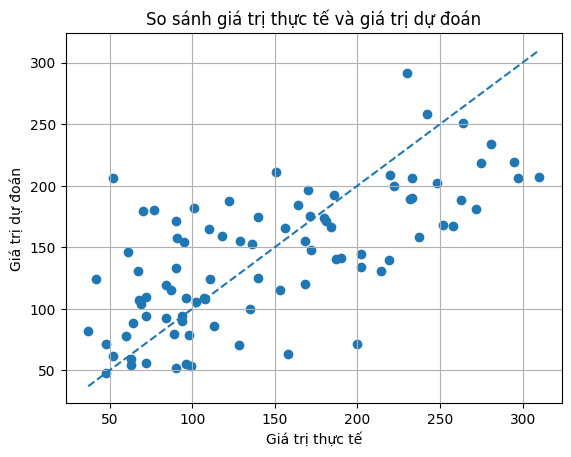

In [1]:
# BÀI 3: LINEAR REGRESSION với DATASET DIABETES
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import ( mean_squared_error, mean_absolute_error, r2_score)

# 1. TẢI DATASET
diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

# 2. CHUYỂN THÀNH DATAFRAME
df = pd.DataFrame(X, columns=diabetes.feature_names)

df["target"] = y

print("\n5 dòng đầu:")
print(df.head())

# 3. KIỂM TRA DỮ LIỆU
print("\nThông tin dataset:")
df.info()

print("\nSố lượng dữ liệu thiếu:")
print(df.isnull().sum())

print("\nThống kê dữ liệu:")
print(df.describe())

# 4. CHIA TRAIN / TEST
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42)

print("\nSố mẫu train:", len(X_train))
print("Số mẫu test:", len(X_test))

# 5. TẠO MÔ HÌNH
model = LinearRegression()

# 6. HUẤN LUYỆN
model.fit(X_train, y_train)

# 7. DỰ ĐOÁN
y_pred = model.predict(X_test)

# 8. ĐÁNH GIÁ
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nKẾT QUẢ ĐÁNH GIÁ")

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)

# 9. SO SÁNH THỰC TẾ - DỰ ĐOÁN
ket_qua = pd.DataFrame({
    "Thực tế": y_test,
    "Dự đoán": y_pred
})

print("\n20 kết quả đầu tiên:")
print(ket_qua.head(20))

# 10. VẼ BIỂU ĐỒ
plt.scatter(y_test, y_pred)

# Đường lý tưởng y = x
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot( [min_value, max_value], [min_value, max_value], linestyle="--")

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")

plt.title("So sánh giá trị thực tế và giá trị dự đoán")

plt.grid()

plt.show()

  Đặc trưng       Hệ số
8        s5  736.198859
2       bmi  542.428759
5        s2  518.062277
3        bp  347.703844
7        s4  275.317902
6        s3  163.419983
9        s6   48.670657
0       age   37.904021
1       sex -241.964362
4        s1 -931.488846


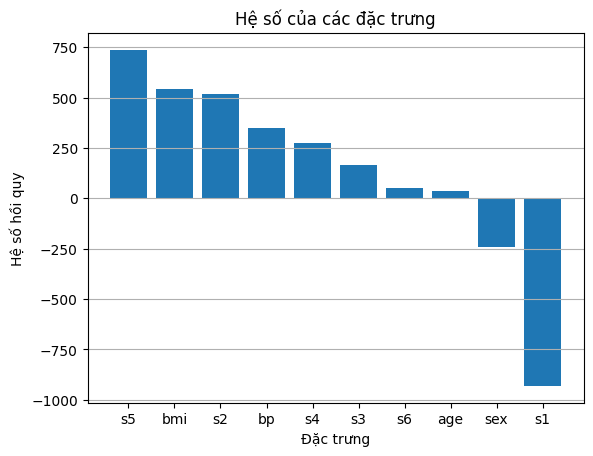

In [2]:
# XEM HỆ SỐ CỦA CÁC ĐẶC TRƯNG
he_so = pd.DataFrame({
    "Đặc trưng": diabetes.feature_names,
    "Hệ số": model.coef_
})

he_so = he_so.sort_values(by="Hệ số", ascending=False)

print(he_so)

plt.bar( he_so["Đặc trưng"], he_so["Hệ số"])

plt.xlabel("Đặc trưng")
plt.ylabel("Hệ số hồi quy")
plt.title("Hệ số của các đặc trưng")

plt.grid(axis="y")

plt.show()